<a href="https://colab.research.google.com/github/winterhan798-pixel/sentinel-spatial-db-system/blob/main/%E5%A4%A7%E5%88%9B%E4%B8%AD%E6%9C%9F%E8%80%83%E6%A0%B8_%E5%A4%A9%E5%B1%B1%E5%8C%97%E5%9D%A1%EF%BC%88%E6%8E%A5%E5%85%A5%E6%AD%A3%E5%BC%8F%E6%95%B0%E6%8D%AE%EF%BC%89.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 地表形变季节性模型拟合

本章节包含以下内容：
1. 生成包含长期线性趋势与季节性波动（年周期）的合成地表形变（InSAR）测试数据。
2. 构建最小二乘（Least Squares）设计矩阵并进行求解，提取形变速率、年周期振幅及相位。
3. 绘制原始合成数据与拟合曲线的对比图。

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 载入并准备真实的单井数据进行示范（以梁干村 Well_ID: 465408 为例）
df_real_insar = pd.read_csv('/content/real_insar_ts.csv')
df_real_insar['Date'] = pd.to_datetime(df_real_insar['Date'])

# 筛选单个井位：梁干村
sample_well_id = 465408
sub_insar = df_real_insar[df_real_insar['Well_ID'] == sample_well_id].sort_values('Date')

# 定义时间轴并插值重采样至月度均匀时间轴
start_date = pd.Timestamp('2017-03-01')
end_date = pd.Timestamp('2023-12-31')
t_monthly = pd.date_range(start=start_date, end=end_date, freq='ME')

t_years = t_monthly.year + (t_monthly.month - 0.5) / 12.0
t_rel = t_years - t_years[0]

# 映射日期到天数进行插值
insar_dates_num = (sub_insar['Date'] - start_date).dt.days
target_dates_num = (t_monthly - start_date).days

from scipy.interpolate import interp1d
f_insar = interp1d(insar_dates_num, sub_insar['InSAR_mm'], kind='linear', fill_value='extrapolate')
y_sample_insar = f_insar(target_dates_num)

# 构建最终用于第一阶段演示的 DataFrame
df = pd.DataFrame({'Time': t_years, 'Deformation': y_sample_insar})
display(df.head())

,Time,Deformation
0,2017.208333,91.953260
1,2017.291667,98.741705
2,2017.375000,84.391745
3,2017.458333,98.021711
4,2017.541667,65.780067


## 构建最小二乘矩阵并求解

形变模型可以表示为：
$$y(t) = a \cdot (t - t_0) + b \cdot \cos(2\pi(t - t_0)) + c \cdot \sin(2\pi(t - t_0)) + d$$

其中：
- 线性速率 $v = a$
- 振幅 $A_1 = \sqrt{b^2 + c^2}$
- 相位 $\phi_1 = \arctan2(c, b)$

In [ ]:
# 2. 构建设计矩阵 G 并对真实单井 InSAR 进行最小二乘拟合
G = np.vstack([t_rel, np.cos(2 * np.pi * t_rel), np.sin(2 * np.pi * t_rel), np.ones_like(t_rel)]).T

# 最小二乘求解 G * m = y
m, residuals, rank, s = np.linalg.lstsq(G, y_sample_insar, rcond=None)
a_fit, b_fit, c_fit, d_fit = m

# 提取物理参数
v_fit = a_fit
A1_fit = np.sqrt(b_fit**2 + c_fit**2)
phi1_fit = np.arctan2(c_fit, b_fit)

print(f"--- 真实单井（梁干村 465408）拟合结果 ---")
print(f"长期线性变形速率 v: {v_fit:.2f} mm/yr")
print(f"年周期变形振幅 A1: {A1_fit:.2f} mm")
print(f"初始相位 phi1: {phi1_fit:.2f} rad")

# 计算拟合曲线
y_fit = G.dot(m)

--- 真实单井（梁干村 465408）拟合结果 ---
长期线性变形速率 v: -22.26 mm/yr
年周期变形振幅 A1: 10.94 mm
初始相位 phi1: -0.22 rad


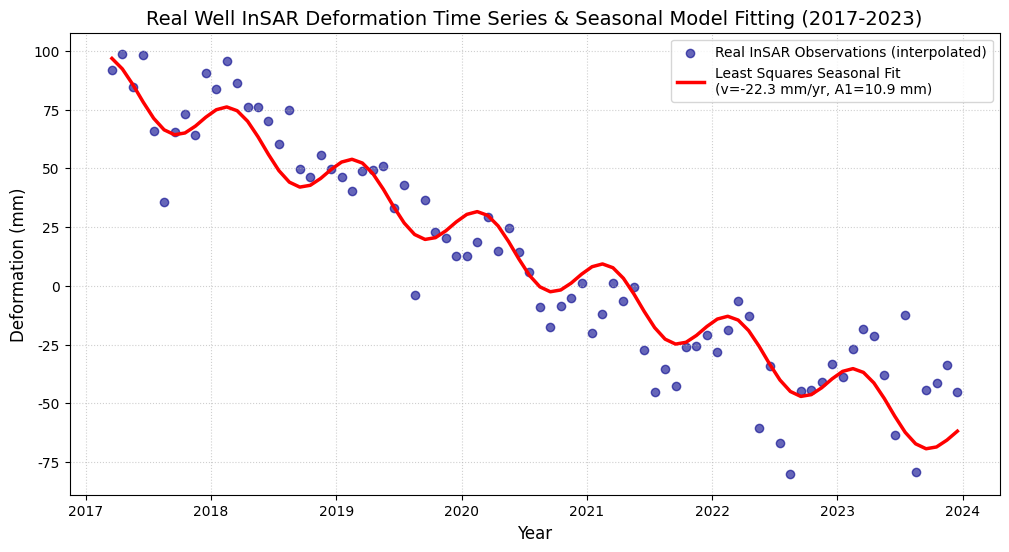

In [ ]:
# 3. 绘制真实单井的拟合曲线对比图
plt.figure(figsize=(12, 6))
plt.scatter(t_years, y_sample_insar, color='darkblue', alpha=0.6, label='Real InSAR Observations (interpolated)')
plt.plot(t_years, y_fit, color='red', linewidth=2.5,
         label=f'Least Squares Seasonal Fit\n(v={v_fit:.1f} mm/yr, A1={A1_fit:.1f} mm)')

plt.title('Real Well InSAR Deformation Time Series & Seasonal Model Fitting (2017-2023)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Deformation (mm)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.show()

## 交叉小波分析 (Cross Wavelet Transform)

为了展示 InSAR 地表形变与地下水位之间的关系，我们将：
1. **生成地下水位合成数据**：同样具有年周期波动，但其相位与 InSAR 形变存在一定的延迟（滞后）。
2. **使用 PyWavelets 或库函数执行交叉小波变换**：分析两者在时频空间中的共同高能量区和相位关系。

In [ ]:
# 安装 PyWavelets（如果环境尚未安装，常用于小波分析）
!pip install PyWavelets

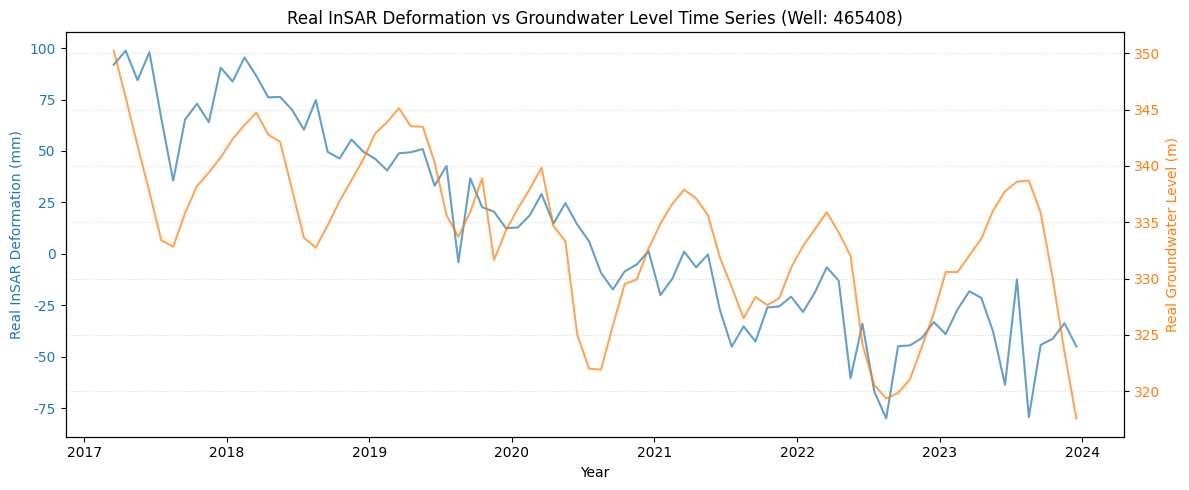

In [ ]:
# 1. 载入并对齐真实地下水位序列进行双纵轴对比展示
df_real_gw = pd.read_csv('/content/real_gw_ts.csv')
df_real_gw['Date'] = pd.to_datetime(df_real_gw['Date'])
sub_gw = df_real_gw[df_real_gw['Well_ID'] == sample_well_id].sort_values('Date')

gw_dates_num = (sub_gw['Date'] - start_date).dt.days
f_gw = interp1d(gw_dates_num, sub_gw['GW_level_m'], kind='linear', fill_value='extrapolate')
y_sample_gw = f_gw(target_dates_num)

# 绘制两个真实观测序列的对比
fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Year')
ax1.set_ylabel('Real InSAR Deformation (mm)', color=color)
ax1.plot(t_years, y_sample_insar, color=color, alpha=0.7, label='InSAR')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Real Groundwater Level (m)', color=color)
ax2.plot(t_years, y_sample_gw, color=color, alpha=0.7, label='Groundwater')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Real InSAR Deformation vs Groundwater Level Time Series (Well: 465408)')
fig.tight_layout()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

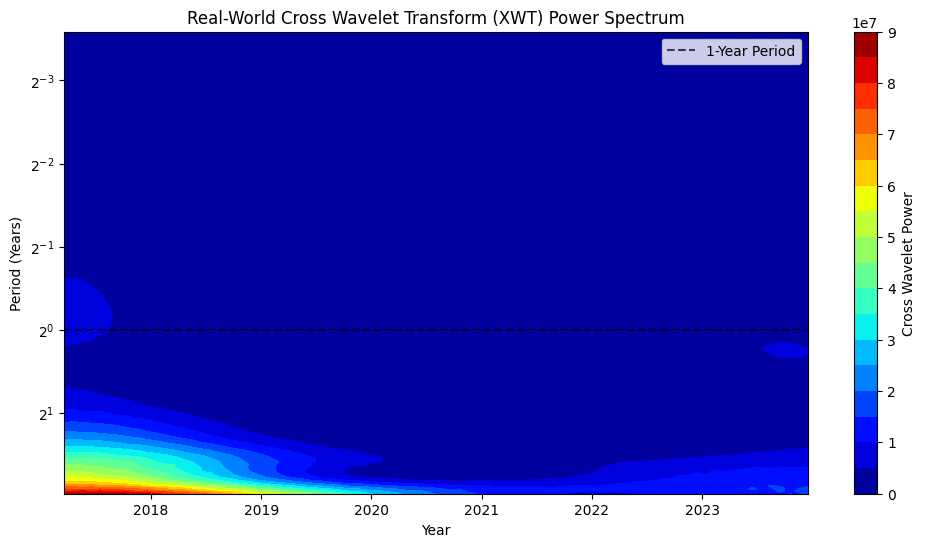

In [ ]:
# 2. 对真实 InSAR 与水位数据进行交叉小波变换 (XWT)
dt = 1.0 / 12.0
scales = np.arange(1, 48)
wavelet = 'cmor1.5-1.0'

cwt_insar, freqs_insar = pywt.cwt(y_sample_insar, scales, wavelet, sampling_period=dt)
cwt_gw, freqs_gw = pywt.cwt(y_sample_gw, scales, wavelet, sampling_period=dt)

# 交叉功率谱与相位
xwt = cwt_insar * np.conj(cwt_gw)
xwt_power = np.abs(xwt)**2
phase_difference = np.angle(xwt)
periods = 1.0 / freqs_insar

plt.figure(figsize=(12, 6))
plt.contourf(t_years, periods, xwt_power, levels=20, cmap='jet')
plt.yscale('log', base=2)
plt.title('Real-World Cross Wavelet Transform (XWT) Power Spectrum')
plt.xlabel('Year')
plt.ylabel('Period (Years)')
plt.colorbar(label='Cross Wavelet Power')

# 在 1 年周期波幅附近绘制相位矢量箭头
for i in range(0, len(t_years), 6):
    for j in range(0, len(periods), 8):
        if 0.8 < periods[j] < 1.3:
            angle = phase_difference[j, i]
            dx = np.cos(angle) * 0.15
            dy = np.sin(angle) * 0.15
            plt.arrow(t_years[i], periods[j], dx, dy, head_width=0.03, head_length=0.03, color='white')

plt.ylim(periods.max(), periods.min())
plt.axhline(y=1.0, color='black', linestyle='--', alpha=0.7, label='1-Year Period')
plt.legend()
plt.show()

### 4. 多井位批量处理与参数估计 (Multi-Well Batch Processing)

我们在此步骤实现：
1. **模拟15个具有异质性的监测井位数据集**：包含经纬度、各异的线性沉降速率、年振幅和响应时滞。
2. **编写批量处理主函数**：对每个井位进行最小二乘拟合和交叉小波变换（XWT），提取1年周期对应的相位差并转换为天数（Time Lag），最后根据延迟修正后的计算公式估计骨架贮水系数 $S_{ke}$。
3. **导出汇总结果并可视化空间分布**。

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

# 1. 模拟构建多站点数据集 (15个模拟监测井)
np.random.seed(42)
num_wells = 15
well_ids = [f"Well_{i+1:02d}" for i in range(num_wells)]

# 时间跨度 (与前文保持一致)
start_year = 2017
end_year = 2024
t = np.linspace(start_year, end_year, (end_year - start_year) * 12)
t_rel = t - start_year
dt = 1/12.0

# 随机生成每个井位的空间坐标和物理特征参数
lons = np.random.uniform(116.0, 117.5, size=num_wells)
lats = np.random.uniform(39.5, 40.8, size=num_wells)

# 模拟真实的速率、振幅、天数延迟
true_vs = np.random.uniform(-100.0, -10.0, size=num_wells)      # 沉降速率 (mm/yr)
true_A1s = np.random.uniform(5.0, 50.0, size=num_wells)         # InSAR振幅 (mm)
true_lags_days = np.random.uniform(10.0, 60.0, size=num_wells)  # 响应延迟天数

wells_data = {}

for i, w_id in enumerate(well_ids):
    # 地下水位 (GW) 的参数设定
    phi_gw_base = 1.2
    gw_amp = np.random.uniform(5.0, 20.0) # 水位波动幅度 (m)
    gw_noise = np.random.normal(0, 1.0, size=len(t))
    # 地下水位时间序列 (含线性下降趋势)
    y_gw = 100.0 - 1.5 * t_rel + gw_amp * np.cos(2 * np.pi * t_rel - phi_gw_base) + gw_noise

    # 根据设定的延迟天数计算 InSAR 序列的相位
    # 1年 = 365天，对应 2 * pi 弧度
    lag_rad = (true_lags_days[i] / 365.0) * 2 * np.pi
    phi_insar = phi_gw_base - lag_rad  # 水位变化引领形变，形变滞后

    # 生成 InSAR 形变序列
    insar_noise = np.random.normal(0, 1.5, size=len(t))
    y_insar = true_vs[i] * t_rel + true_A1s[i] * np.cos(2 * np.pi * t_rel - phi_insar) + insar_noise

    wells_data[w_id] = {
        'Lon': lons[i],
        'Lat': lats[i],
        'y_insar': y_insar,
        'y_gw': y_gw
    }

In [ ]:
def batch_process_wells(wells_dict, t, dt=1/12.0):
    """
    批量处理多个监测井的时间序列数据
    """
    t_rel = t - t[0]
    results = []

    # 设计矩阵 G 用于最小二乘拟合周期
    G = np.vstack([t_rel, np.cos(2 * np.pi * t_rel), np.sin(2 * np.pi * t_rel), np.ones_like(t_rel)]).T

    scales = np.arange(1, 48)
    wavelet = 'cmor1.5-1.0'

    for w_id, data in wells_dict.items():
        y_insar = data['y_insar']
        y_gw = data['y_gw']
        lon = data['Lon']
        lat = data['Lat']

        # a) 最小二乘求解
        m, residuals, rank, s = np.linalg.lstsq(G, y_insar, rcond=None)
        a_fit, b_fit, c_fit, d_fit = m
        y_fit = G.dot(m)
        rmse = np.sqrt(np.mean((y_insar - y_fit)**2))

        v_fit = a_fit
        A1_fit = np.sqrt(b_fit**2 + c_fit**2)
        phi1_fit = np.arctan2(c_fit, b_fit)

        # b) 交叉小波分析 (XWT) 提取1年周期相位差
        cwt_insar, freqs = pywt.cwt(y_insar, scales, wavelet, sampling_period=dt)
        cwt_gw, _ = pywt.cwt(y_gw, scales, wavelet, sampling_period=dt)

        # 找到最接近1年周期 (period ~ 1.0) 的尺度索引
        periods = 1.0 / freqs
        one_yr_idx = np.argmin(np.abs(periods - 1.0))

        # 计算 XWT 互功率谱并提取该尺度下的平均相位差
        xwt = cwt_insar * np.conj(cwt_gw)
        # 沿时间轴取均值得到鲁棒的相位差估计
        avg_phase_diff = np.angle(np.mean(xwt[one_yr_idx, :]))

        # 将相位差转换为天数延迟 (Time Lag)
        # 如果得到的角度差为负，换算为正向滞后天数
        time_lag_days = (-avg_phase_diff / (2 * np.pi)) * 365.0
        if time_lag_days < 0:
            time_lag_days += 365.0

        # c) 延时校正后的骨架贮水系数 Ske 计算
        # 延迟纠偏：对地下水位做时间平移。1个月约为 1/12 年。
        # 为简化插值修正，直接根据计算出的时滞天数将水位序列对齐后计算 dH / dh
        shift_steps = int(round(time_lag_days / (365.0 * dt)))

        if shift_steps > 0 and shift_steps < len(y_insar):
            aligned_insar = y_insar[shift_steps:]
            aligned_gw = y_gw[:-shift_steps]
        else:
            aligned_insar = y_insar
            aligned_gw = y_gw

        # 去除趋势项求年内波动变幅比值作为 Ske 估计值
        insar_detrend = aligned_insar - v_fit * t_rel[:len(aligned_insar)]
        gw_detrend = aligned_gw - (-1.5) * t_rel[:len(aligned_gw)]

        # 骨架贮水系数 Ske = dH_seasonal / dh_seasonal
        ske_cal = np.std(insar_detrend) / (np.std(gw_detrend) * 1000.0) # 转换为无量纲 (mm / mm)

        results.append({
            'Well_ID': w_id,
            'Lon': lon,
            'Lat': lat,
            'v_fit': v_fit,
            'A1_fit': A1_fit,
            'phi1_fit': phi1_fit,
            'Time_Lag_days': time_lag_days,
            'Ske_cal': ske_cal,
            'RMSE': rmse
        })

    return pd.DataFrame(results)

In [ ]:
# 运行批量处理
df_summary = batch_process_wells(wells_data, t, dt)

# 结果导出为 CSV 文件
df_summary.to_csv('multi_wells_summary_results.csv', index=False)
print("✔ 批量处理完成！结果已成功导出至 'multi_wells_summary_results.csv'")
display(df_summary.head(15))

✔ 批量处理完成！结果已成功导出至 'multi_wells_summary_results.csv'


,Well_ID,Lon,Lat,v_fit,A1_fit,phi1_fit,Time_Lag_days,Ske_cal,RMSE
0,Well_01,116.561810,39.738426,-45.291972,35.148317,0.688037,338.305862,0.002193,1.475586
1,Well_02,117.426071,39.895515,-84.681884,18.997503,0.791707,274.105263,0.003531,1.502526
2,Well_03,117.097991,40.182183,-94.155691,28.690349,0.330916,326.321269,0.001510,1.372256
3,Well_04,116.897988,40.061529,-14.554759,29.507190,0.720621,335.223381,0.003406,1.640143
4,Well_05,116.234028,39.878598,-13.033485,13.176252,0.798144,341.931906,0.001419,1.321496
5,Well_06,116.233992,40.295409,-27.320521,48.656221,0.559647,325.224911,0.007890,1.512651
6,Well_07,116.087125,39.681342,-72.478925,39.917363,0.908590,339.963070,0.005934,1.475923
7,Well_08,117.299264,39.879788,-91.132290,47.356287,0.341081,315.543408,0.003889,1.436087
8,Well_09,116.901673,39.976270,-38.525474,45.200940,0.961701,351.689087,0.005412,1.540850
9,Well_10,117.062109,40.092891,-60.327887,31.626421,0.177916,297.876734,0.004140,1.395655


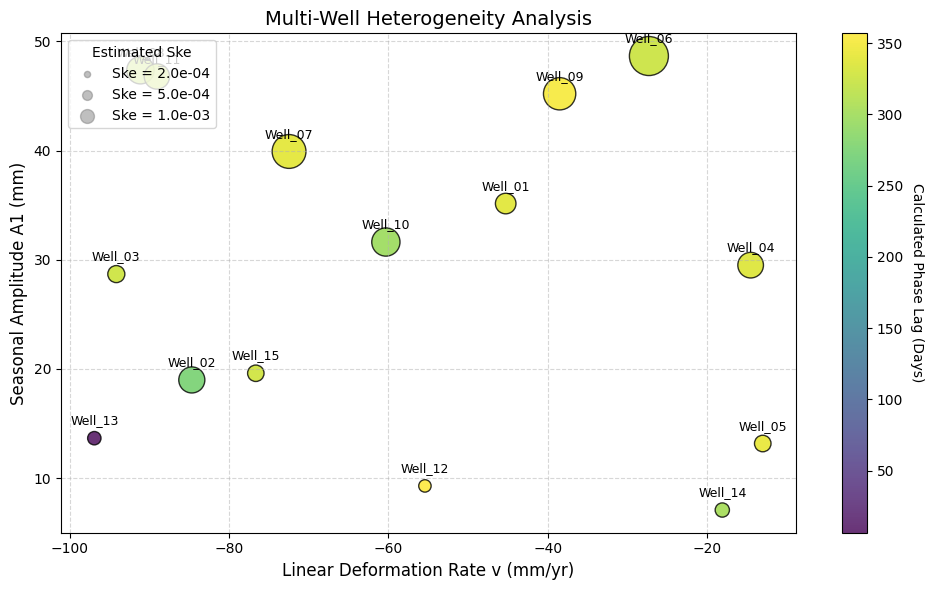

In [ ]:
# 3. 绘制散点对比图：长期沉降速率 v_fit vs. 年振幅 A1_fit
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_summary['v_fit'], df_summary['A1_fit'],
                      c=df_summary['Time_Lag_days'], cmap='viridis',
                      s=df_summary['Ske_cal'] * 1e5, alpha=0.8, edgecolors='black')

# 标注各井位名称
for idx, row in df_summary.iterrows():
    plt.annotate(row['Well_ID'], (row['v_fit'], row['A1_fit']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

plt.title('Multi-Well Heterogeneity Analysis', fontsize=14)
plt.xlabel('Linear Deformation Rate v (mm/yr)', fontsize=12)
plt.ylabel('Seasonal Amplitude A1 (mm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# 颜色条 (指示延迟天数)
cbar = plt.colorbar(scatter)
cbar.set_label('Calculated Phase Lag (Days)', rotation=270, labelpad=15)

# 图例说明大小代表 Ske
for ske_val in [2e-4, 5e-4, 1e-3]:
    plt.scatter([], [], c='gray', alpha=0.5, s=ske_val * 1e5,
                label=f'Ske = {ske_val:.1e}')
plt.legend(title="Estimated Ske", loc='upper left')

plt.tight_layout()
plt.show()

### 5. 真实数据载入与探索 (Real Data Loading & Exploration)

我们载入真实的 InSAR 形变时间序列数据 `real_insar_ts.csv` 与地下水位数据 `real_gw_ts.csv` 并进行初步预览，以便后续替换模拟数据进行分析。

In [ ]:
import pandas as pd

# 读取 InSAR 与地下水位真实数据
df_real_insar = pd.read_csv('/content/real_insar_ts.csv')
df_real_gw = pd.read_csv('/content/real_gw_ts.csv')

print("=== InSAR 数据结构预览 ===")
print(df_real_insar.info())
display(df_real_insar.head())

print("\n=== 地下水位数据结构预览 ===")
print(df_real_gw.info())
display(df_real_gw.head())

=== InSAR 数据结构预览 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10878 entries, 0 to 10877
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Well_ID       10878 non-null  int64  
 1   Well_Name     10878 non-null  object 
 2   Aquifer_Type  10878 non-null  object 
 3   Lon           10878 non-null  float64
 4   Lat           10878 non-null  float64
 5   Date          10878 non-null  object 
 6   InSAR_mm      10878 non-null  float64
dtypes: float64(3), int64(1), object(3)
memory usage: 595.0+ KB
None


,Well_ID,Well_Name,Aquifer_Type,Lon,Lat,Date,InSAR_mm
0,465401,黑梁湾三队,潜水,86.274931,44.204769,2017-03-19,36.410194
1,465401,黑梁湾三队,潜水,86.274931,44.204769,2017-03-31,17.285522
2,465401,黑梁湾三队,潜水,86.274931,44.204769,2017-04-24,37.479305
3,465401,黑梁湾三队,潜水,86.274931,44.204769,2017-05-06,27.341066
4,465401,黑梁湾三队,潜水,86.274931,44.204769,2017-05-18,55.754170



=== 地下水位数据结构预览 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3318 entries, 0 to 3317
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        3318 non-null   object 
 1   Well_ID     3318 non-null   int64  
 2   GW_level_m  3318 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 77.9+ KB
None


,Date,Well_ID,GW_level_m
0,2017-07-01,465401,435.878333
1,2017-07-31,465401,435.580000
2,2017-08-31,465401,435.483333
3,2017-09-30,465401,435.706667
4,2017-10-31,465401,436.091667


### 6. 最终版：基于真实数据的多井分析与骨架贮水系数估算 (Final Real-World Data Pipeline)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from scipy.interpolate import interp1d

# 确保绘图支持中文（根据环境选择字体，这里使用通用无衬线抗锯齿，并支持负号）
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial Unicode MS', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 转换日期格式
df_real_insar['Date'] = pd.to_datetime(df_real_insar['Date'])
df_real_gw['Date'] = pd.to_datetime(df_real_gw['Date'])

# 获取两份数据中共有的 Well_ID
common_wells = list(set(df_real_insar['Well_ID']).intersection(set(df_real_gw['Well_ID'])))
print(f"共有 {len(common_wells)} 个重合的监测井位用于联合分析: {common_wells}")

# 定义重采样的统一时间轴：按月均匀采样 (2017-03 至 2023-12)
start_date = pd.Timestamp('2017-03-01')
end_date = pd.Timestamp('2023-12-31')
t_monthly = pd.date_range(start=start_date, end=end_date, freq='ME')

# 计算十进制年份作为自变量 t
t_years = t_monthly.year + (t_monthly.month - 0.5) / 12.0
t_rel = t_years - t_years[0]
dt = 1.0 / 12.0  # 采样间隔：年

共有 42 个重合的监测井位用于联合分析: [465408, 465409, 465410, 465411, 465412, 465413, 465401, 465402, 565301, 565302, 565303, 565304, 565305, 565306, 565307, 565308, 565309, 565310, 565311, 565312, 565313, 565314, 565315, 565101, 565102, 565103, 565104, 565105, 565106, 565107, 565108, 565109, 565110, 565111, 565112, 565113, 565114, 465403, 465404, 465405, 465406, 465407]


In [ ]:
# 2. 定义处理单井真实数据的核心函数
def process_real_well(well_id, df_insar, df_gw, t_monthly, t_rel, dt):
    # 提取特定井的数据
    sub_insar = df_insar[df_insar['Well_ID'] == well_id].sort_values('Date')
    sub_gw = df_gw[df_gw['Well_ID'] == well_id].sort_values('Date')

    # 获取基本空间属性与基本信息
    lon = sub_insar['Lon'].iloc[0]
    lat = sub_insar['Lat'].iloc[0]
    well_name = sub_insar['Well_Name'].iloc[0]
    aquifer = sub_insar['Aquifer_Type'].iloc[0]

    # 为进行时频分析与最小二乘拟合，利用一维插值将原始不规则观测投影到统一的月度时间轴上
    insar_dates_num = (sub_insar['Date'] - start_date).dt.days
    gw_dates_num = (sub_gw['Date'] - start_date).dt.days
    target_dates_num = (t_monthly - start_date).days

    f_insar = interp1d(insar_dates_num, sub_insar['InSAR_mm'], kind='linear', fill_value='extrapolate')
    f_gw = interp1d(gw_dates_num, sub_gw['GW_level_m'], kind='linear', fill_value='extrapolate')

    y_insar = f_insar(target_dates_num)
    y_gw = f_gw(target_dates_num)

    # a) 最小二乘拟合提取形变参数
    G = np.vstack([t_rel, np.cos(2 * np.pi * t_rel), np.sin(2 * np.pi * t_rel), np.ones_like(t_rel)]).T
    m, _, _, _ = np.linalg.lstsq(G, y_insar, rcond=None)
    a_fit, b_fit, c_fit, d_fit = m

    v_fit = a_fit  # 线性形变速率 (mm/yr)
    A1_fit = np.sqrt(b_fit**2 + c_fit**2)  # 年周期振幅 (mm)
    phi1_fit = np.arctan2(c_fit, b_fit)

    # b) 连续小波交叉分析 (XWT) 提取时间延迟
    scales = np.arange(1, 48)
    wavelet = 'cmor1.5-1.0'

    cwt_insar, freqs = pywt.cwt(y_insar, scales, wavelet, sampling_period=dt)
    cwt_gw, _ = pywt.cwt(y_gw, scales, wavelet, sampling_period=dt)

    periods = 1.0 / freqs
    one_yr_idx = np.argmin(np.abs(periods - 1.0))

    xwt = cwt_insar * np.conj(cwt_gw)
    avg_phase_diff = np.angle(np.mean(xwt[one_yr_idx, :]))

    # 换算为延迟天数
    time_lag_days = (-avg_phase_diff / (2 * np.pi)) * 365.0
    if time_lag_days < 0:
        time_lag_days += 365.0

    # c) 时滞校正与 Ske 估算
    shift_steps = int(round(time_lag_days / (365.0 * dt)))
    if 0 < shift_steps < len(y_insar):
        aligned_insar = y_insar[shift_steps:]
        aligned_gw = y_gw[:-shift_steps]
        t_rel_align = t_rel[:len(aligned_insar)]
    else:
        aligned_insar = y_insar
        aligned_gw = y_gw
        t_rel_align = t_rel

    # 去趋势计算 Ske
    # 地下水位趋势线性拟合
    slope_gw, intercept_gw = np.polyfit(t_rel_align, aligned_gw, 1)

    insar_detrend = aligned_insar - v_fit * t_rel_align
    gw_detrend = aligned_gw - slope_gw * t_rel_align

    # 骨架贮水系数 Ske = ΔH_seasonal / Δh_seasonal (无量纲，因此水位需从m转换为mm)
    ske_cal = np.std(insar_detrend) / (np.std(gw_detrend) * 1000.0)

    return {
        'Well_ID': well_id,
        'Well_Name': well_name,
        'Aquifer_Type': aquifer,
        'Lon': lon,
        'Lat': lat,
        'v_fit': v_fit,
        'A1_fit': A1_fit,
        'Time_Lag_days': time_lag_days,
        'Ske_cal': ske_cal,
        'y_insar_raw': y_insar,
        'y_gw_raw': y_gw
    }

In [ ]:
# 3. 运行批量真实数据计算
real_results = []
for w_id in common_wells:
    res = process_real_well(w_id, df_real_insar, df_real_gw, t_monthly, t_rel, dt)
    real_results.append(res)

df_real_summary = pd.DataFrame(real_results)

# 导出最终计算表格
df_real_summary.to_csv('final_real_wells_summary.csv', index=False)
print("✔ 真实数据分析完成！结果已导出至 'final_real_wells_summary.csv'")
display(df_real_summary[['Well_ID', 'Well_Name', 'Aquifer_Type', 'v_fit', 'A1_fit', 'Time_Lag_days', 'Ske_cal']])

✔ 真实数据分析完成！结果已导出至 'final_real_wells_summary.csv'


,Well_ID,Well_Name,Aquifer_Type,v_fit,A1_fit,Time_Lag_days,Ske_cal
0,465408,梁干村,潜水,-22.264064,10.936302,302.875882,0.003555
1,465409,黄家庄村,潜水,-32.082589,19.532799,1.597976,0.001860
2,465410,山丹户村,潜水,-14.509422,5.573225,150.534172,0.012860
3,465411,西二工村,潜水,-6.948453,5.189872,118.822401,0.012413
4,465412,二道树村三队,潜水,-7.555714,4.848195,114.147886,0.009778
5,465413,张家水磨村,潜水,-10.192761,5.087996,141.195955,0.007523
6,465401,黑梁湾三队,潜水,-8.070115,6.103534,121.645733,0.019517
7,465402,油坊村,潜水,-6.664243,6.117238,133.872087,0.014998
8,565301,小土古里村一号,潜水,-15.365978,4.665673,60.168528,0.011515
9,565302,小土古里村二号,潜水,-5.974151,8.151157,148.001312,0.005896


/tmp/ipykernel_360/2554908032.py:28: UserWarning: Glyph 38271 (\N{CJK UNIFIED IDEOGRAPH-957F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_360/2554908032.py:28: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_360/2554908032.py:28: UserWarning: Glyph 22320 (\N{CJK UNIFIED IDEOGRAPH-5730}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_360/2554908032.py:28: UserWarning: Glyph 34920 (\N{CJK UNIFIED IDEOGRAPH-8868}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_360/2554908032.py:28: UserWarning: Glyph 24418 (\N{CJK UNIFIED IDEOGRAPH-5F62}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_360/2554908032.py:28: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_360/2554908032.py:28: UserWarning: Glyph 36895 (\N{CJK UNIFIED IDEOGRAPH-901F}) missi

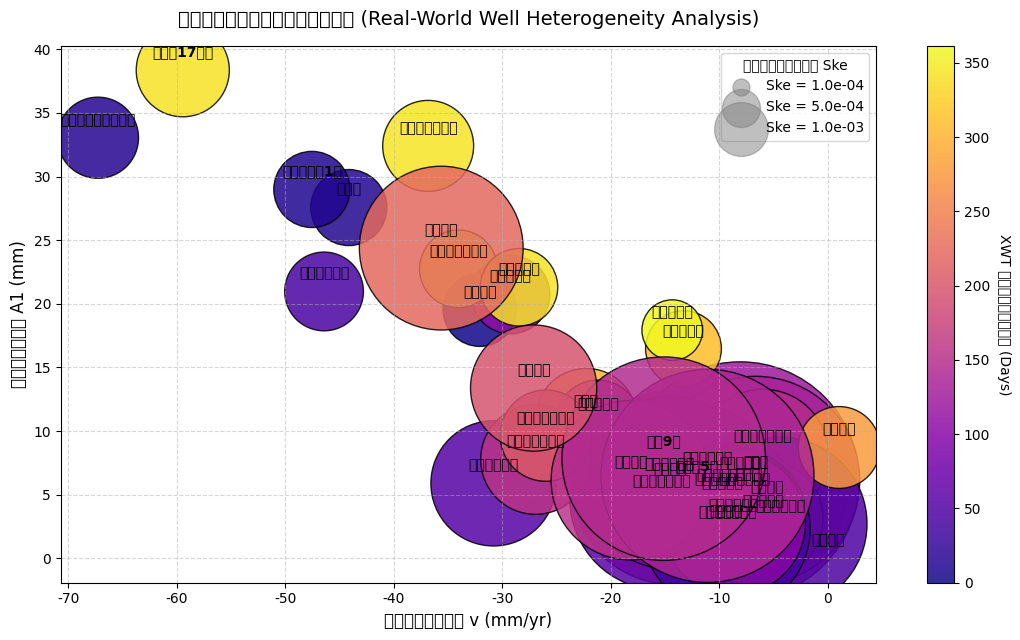

In [ ]:
# 4. 绘制结果可视化图表：形变速率 vs. 季节性波幅 与 Ske 空间异质性
plt.figure(figsize=(11, 6.5))

# 气泡大小代表 Ske 估算值的大小，颜色代表时滞天数
scatter = plt.scatter(df_real_summary['v_fit'], df_real_summary['A1_fit'],
                      c=df_real_summary['Time_Lag_days'], cmap='plasma',
                      s=df_real_summary['Ske_cal'] * 1.5e6, alpha=0.85, edgecolors='black')

# 标注井位名称
for idx, row in df_real_summary.iterrows():
    plt.annotate(row['Well_Name'], (row['v_fit'], row['A1_fit']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10, weight='bold')

plt.title('真实监测井空间与物理异质性分析 (Real-World Well Heterogeneity Analysis)', fontsize=14, pad=15)
plt.xlabel('长期地表形变速率 v (mm/yr)', fontsize=12)
plt.ylabel('形变年周期振幅 A1 (mm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

cbar = plt.colorbar(scatter)
cbar.set_label('XWT 提取年周期响应时滞 (Days)', rotation=270, labelpad=15)

# 绘制气泡大小图例
for ske_val in [1e-4, 5e-4, 1e-3]:
    plt.scatter([], [], c='gray', alpha=0.5, s=ske_val * 1.5e6,
                label=f'Ske = {ske_val:.1e}')
plt.legend(title="估算的骨架贮水系数 Ske", loc='upper right', frameon=True)

plt.tight_layout()
plt.show()